In [2]:
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def tidy(path, name):
    df = pd.read_csv(path, skiprows=4)          # World Bank CSVs have 4 header rows
    df = df[df["Country Code"].isin(["USA", "CHN"])]
    years = [str(y) for y in range(1982, 2023)]
    df = df.melt(id_vars=["Country Code"], value_vars=years,
                 var_name="year", value_name=name)
    df["year"] = df["year"].astype(int)
    return df.rename(columns={"Country Code": "country"})

data = tidy("gdp.csv", "gdp_per_capita").merge(
       tidy("life.csv", "life_expectancy"), on=["country", "year"])
data.head()

,country,year,gdp_per_capita,life_expectancy
0,CHN,1982,203.722788,65.249000
1,USA,1982,14433.787727,74.360976
2,CHN,1983,225.865347,65.728000
3,USA,1983,15543.893717,74.463415
4,CHN,1984,251.192686,66.148000


In [3]:
us = data[data.country == "USA"]
cn = data[data.country == "CHN"]

for name, g in [("USA", us), ("China", cn)]:
    r, p = stats.pearsonr(g.gdp_per_capita, g.life_expectancy)
    print(name, "r =", round(r, 3), "p =", p)

us_lin = stats.linregress(us.gdp_per_capita, us.life_expectancy)
cn_lin = stats.linregress(cn.gdp_per_capita, cn.life_expectancy)
cn_log = stats.linregress(np.log(cn.gdp_per_capita), cn.life_expectancy)

print("USA linear R^2:", round(us_lin.rvalue**2, 3))
print("China linear R^2:", round(cn_lin.rvalue**2, 3))
print("China log R^2:", round(cn_log.rvalue**2, 3))

USA r = 0.839 p = 7.771856651529665e-12
China r = 0.849 p = 2.2260206609516365e-12
USA linear R^2: 0.703
China linear R^2: 0.721
China log R^2: 0.965


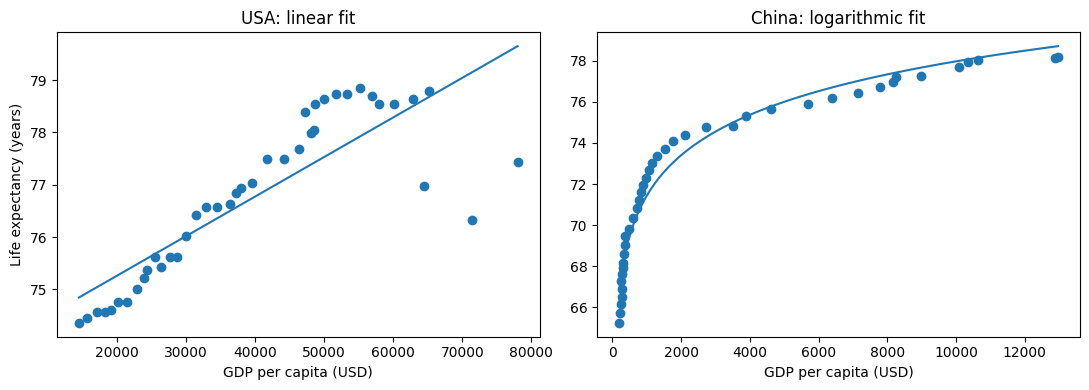

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

xs = np.linspace(us.gdp_per_capita.min(), us.gdp_per_capita.max(), 100)
ax[0].scatter(us.gdp_per_capita, us.life_expectancy)
ax[0].plot(xs, us_lin.intercept + us_lin.slope * xs)
ax[0].set(title="USA: linear fit", xlabel="GDP per capita (USD)", ylabel="Life expectancy (years)")

xs = np.linspace(cn.gdp_per_capita.min(), cn.gdp_per_capita.max(), 100)
ax[1].scatter(cn.gdp_per_capita, cn.life_expectancy)
ax[1].plot(xs, cn_log.intercept + cn_log.slope * np.log(xs))
ax[1].set(title="China: logarithmic fit", xlabel="GDP per capita (USD)")

plt.tight_layout()
plt.savefig("fits.png", dpi=150)

In [5]:
import sqlite3
con = sqlite3.connect("gdp_life.db")
data.to_sql("indicators", con, if_exists="replace", index=False)

query = """
SELECT country,
       (year / 10) * 10 AS decade,
       ROUND(AVG(gdp_per_capita), 0) AS avg_gdp,
       ROUND(AVG(life_expectancy), 1) AS avg_life_expectancy
FROM indicators
GROUP BY country, decade
ORDER BY country, decade;
"""
pd.read_sql(query, con)

,country,decade,avg_gdp,avg_life_expectancy
0,CHN,1980,263.0,66.7
1,CHN,1990,570.0,70.1
2,CHN,2000,2010.0,73.9
3,CHN,2010,7750.0,76.8
4,CHN,2020,12162.0,78.1
5,USA,1980,18590.0,74.6
6,USA,1990,28522.0,75.8
7,USA,2000,42692.0,77.5
8,USA,2010,56180.0,78.7
9,USA,2020,71305.0,76.9
